In [15]:
import xarray as xr
import rioxarray
import rasterio
import matplotlib.pyplot as plt
import geopandas as gpd
gl = gpd.read_file('/Users/jkingslake/Documents/science/QGIS/Quantarctica3/Glaciology/MEaSUREs Antarctic Boundaries/GroundingLine_Antarctica_v2.shp')

In [18]:
rioxarray.open_rasterio('/Users/jkingslake/Documents/data/UMelt/UMelt_Timeseries/MeltSeason_1920/UMelt_Timeseries_1920_tile2.tif')


<xarray.DataArray (band: 201, y: 4864, x: 4864)> Size: 5GB
[4755357696 values with dtype=uint8]
Coordinates:
  * band         (band) int64 2kB 1 2 3 4 5 6 7 ... 195 196 197 198 199 200 201
  * y            (y) float64 39kB 3.333e+06 3.333e+06 ... 9.022e+05 9.018e+05
  * x            (x) float64 39kB -9.012e+05 -9.008e+05 ... 1.53e+06 1.53e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    millis:         1572588000000
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      ('UMelt_1572588000000', 'UMelt_1572674400000', 'UMelt_157...

In [11]:
import warnings
from pathlib import Path

import dask.array as dsa
import numpy as np
import pandas as pd
import rioxarray
import xarray as xr

umelt_dir = Path("/Users/jkingslake/Documents/data/UMelt/UMelt_Timeseries")


def open_umelt_tile(f, chunks=256):
    """Open one UMelt tile. Each band is one timestep, named 'UMelt_<unix ms>'.

    256 px chunks match the GeoTIFF blocks and line up with every season's tile edges.
    """
    da = rioxarray.open_rasterio(f, chunks={"band": -1, "y": chunks, "x": chunks})
    millis = [int(name.split("_")[-1]) for name in da.attrs.pop("long_name")]
    da.attrs.pop("millis", None)  # first timestep only, present in some tiles
    return (
        da.rename(band="time")
        .assign_coords(time=pd.to_datetime(millis, unit="ms"))
        .rename("melt")
    )


def open_umelt_season(season_dir):
    """Mosaic the tiles of one melt season into a lazy (time, y, x) DataArray.

    Tiles share a 500 m grid and don't overlap, but the tiling changes between seasons
    and some all-ocean tiles are missing, so gaps are filled with 0 (no melt).
    """
    tiles = [open_umelt_tile(f) for f in sorted(Path(season_dir).glob("*.tif"))]
    template = tiles[0]
    assert all(t.time.equals(template.time) for t in tiles), "tiles have different timestamps"

    def empty_tile(y, x):
        data = dsa.zeros((template.time.size, y.size, x.size), dtype=template.dtype,
                         chunks=template.data.chunksize)
        return xr.DataArray(data, dims=template.dims, name=template.name, attrs=template.attrs,
                            coords={"time": template.time, "y": y, "x": x,
                                    "spatial_ref": template.spatial_ref})

    # arrange tiles in rows (top to bottom) and columns (left to right) by their corner coords
    by_corner = {(float(t.y[0]), float(t.x[0])): t for t in tiles}
    row_y = {float(t.y[0]): t.y for t in tiles}
    col_x = {float(t.x[0]): t.x for t in tiles}
    rows = [
        [by_corner[(y0, x0)] if (y0, x0) in by_corner else empty_tile(row_y[y0], col_x[x0])
         for x0 in sorted(col_x)]
        for y0 in sorted(row_y, reverse=True)
    ]
    return xr.combine_nested(rows, concat_dim=["y", "x"], combine_attrs="override")


# stack all seasons along time, padding each to the union of their extents with 0 (no melt)
seasons = [open_umelt_season(d) for d in sorted(umelt_dir.glob("MeltSeason_*"))]
x = np.unique(np.concatenate([s.x for s in seasons]))
y = np.unique(np.concatenate([s.y for s in seasons]))[::-1]  # keep north-up
with warnings.catch_warnings():
    # padding the smaller seasons adds chunks, which dask flags; that's expected here
    warnings.simplefilter("ignore", dsa.PerformanceWarning)
    melt = xr.concat([s.reindex(x=x, y=y, fill_value=0) for s in seasons], dim="time")

# crop to the study area; y runs north to south, so its slice goes from ymax down to ymin
xmin, ymin, xmax, ymax = -2465679.2272243868, 1108472.324787593, -2278502.197802196, 1291624.0417490914
melt = melt.sel(x=slice(xmin, xmax), y=slice(ymax, ymin))
melt

<xarray.DataArray 'melt' (time: 1166, y: 366, x: 374)> Size: 160MB
dask.array<getitem, shape=(1166, 366, 374), dtype=uint8, chunksize=(287, 256, 256), chunktype=numpy.ndarray>
Coordinates:
  * time         (time) datetime64[ns] 9kB 2016-11-01T06:00:00 ... 2021-03-30...
  * y            (y) float64 3kB 1.291e+06 1.291e+06 ... 1.109e+06 1.109e+06
  * x            (x) float64 3kB -2.465e+06 -2.465e+06 ... -2.279e+06 -2.279e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [12]:
melt.load()

<xarray.DataArray 'melt' (time: 1166, y: 366, x: 374)> Size: 160MB
array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
...
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]]], shape=(1166, 366, 374), dtype=uint8)
Coordinates:
  * time         (time) datetime64[ns] 9kB 2016-11-01T06:00:00 ... 2021-03-30...
  * y            (y) float64 3kB 1.291e+06 1.291e+06 ... 1.109e+06 1.109e+06
  * x            (x) float64 3kB -2.465e+06 -2.465e+06 ... -2.279e+06 -2.279e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

<Axes: title={'center': 'spatial_ref = 0'}, xlabel='x', ylabel='y'>

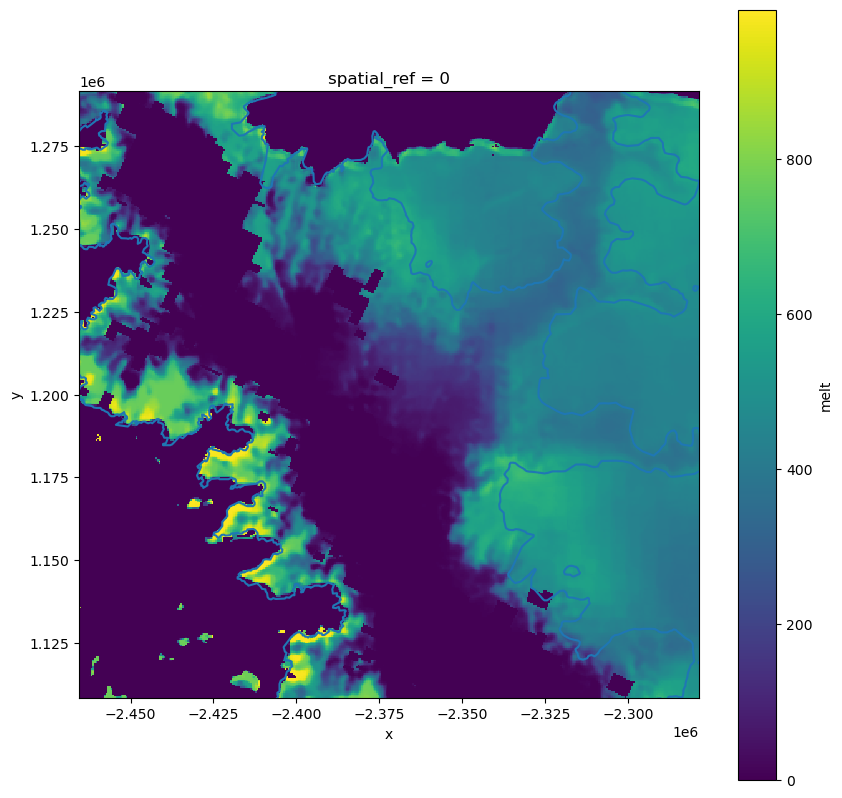

In [19]:
fig, ax = plt.subplots(figsize=(10, 10))
melt.sum(dim="time").plot(ax = ax)
gl.boundary.plot(ax = ax)


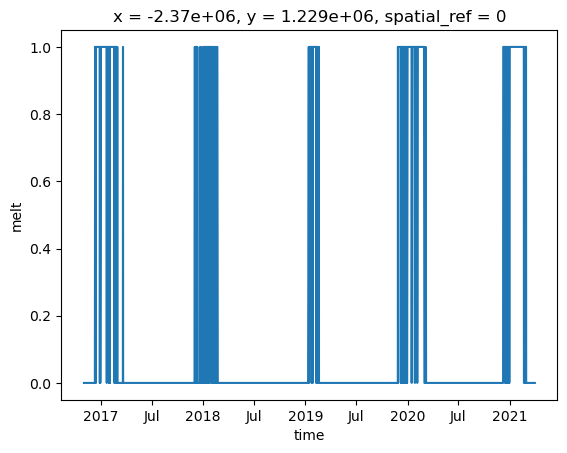

In [4]:
melt.sel(y =1229088, x = -2369934, method = "nearest").plot()

In [10]:
melt.rio.clip([-2373085.2101596803,1226774.8372636077,-2368617.849366373,1222403.5487454252 ])#.sel(time = '2017-01-01', method = "nearest").plot()

/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/rasterio/features.py:336: ShapeSkipWarning: Invalid or empty shape -2373085.2101596803 at index 0 will not be rasterized.
  warnings.warn(
/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/rasterio/features.py:336: ShapeSkipWarning: Invalid or empty shape 1226774.8372636077 at index 1 will not be rasterized.
  warnings.warn(
/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/rasterio/features.py:336: ShapeSkipWarning: Invalid or empty shape -2368617.849366373 at index 2 will not be rasterized.
  warnings.warn(
/Users/jkingslake/.local/share/mamba/envs/pdem_tools/lib/python3.13/site-packages/rasterio/features.py:336: ShapeSkipWarning: Invalid or empty shape 1222403.5487454252 at index 3 will not be rasterized.
  warnings.warn(


NoDataInBounds: No data found in bounds. Data variable: melt

In [34]:
melt

<xarray.DataArray 'melt' (time: 1166, y: 366, x: 374)> Size: 160MB
array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
...
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]]], shape=(1166, 366, 374), dtype=uint8)
Coordinates:
  * time         (time) datetime64[ns] 9kB 2016-11-01T06:00:00 ... 2021-03-30...
  * y            (y) float64 3kB 1.291e+06 1.291e+06 ... 1.109e+06 1.109e+06
  * x            (x) float64 3kB -2.465e+06 -2.465e+06 ... -2.279e+06 -2.279e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [20]:
def melt_onset_freeze(melt, min_run=3):
    """Melt onset and freeze-up dates for each melt season and pixel.

    A day is a melt day if any observation that day shows melt. Onset is the first day of the
    season's first run of at least `min_run` consecutive melt days, and freeze-up is the last day
    of its last such run (NaT where there is none). Runs are counted over observed days, so
    they step over days with no data. The *_censored flags mark onsets on the first day of the
    record and freeze-ups on the last day, where the true date may lie outside the record.
    """
    daily = melt.groupby(melt.time.dt.floor("D")).max().rename(floor="time")

    def one_season(d):
        run_end = d.rolling(time=min_run).sum() == min_run  # True on the last day of each run
        run_start = run_end.shift(time=1 - min_run, fill_value=False)  # True on the first day
        found = run_end.any("time")
        return xr.Dataset({
            "onset": run_start.idxmax("time").where(found),
            "freeze": run_end.isel(time=slice(None, None, -1)).idxmax("time").where(found),
            "onset_censored": run_start.isel(time=0, drop=True),
            "freeze_censored": run_end.isel(time=-1, drop=True),
        })

    # label each season by the year it starts in, e.g. 2016 for 2016/17
    season = (daily.time.dt.year - (daily.time.dt.month < 7)).rename("season")
    return daily.groupby(season).map(one_season).assign_attrs(min_run=min_run)


melt_dates = melt_onset_freeze(melt.load())
melt_dates

<xarray.Dataset> Size: 12MB
Dimensions:          (season: 5, y: 366, x: 374)
Coordinates:
  * season           (season) int64 40B 2016 2017 2018 2019 2020
  * y                (y) float64 3kB 1.291e+06 1.291e+06 ... 1.109e+06 1.109e+06
  * x                (x) float64 3kB -2.465e+06 -2.465e+06 ... -2.279e+06
    spatial_ref      int64 8B 0
Data variables:
    onset            (season, y, x) datetime64[ns] 5MB 2016-12-02 ... 2020-11-01
    freeze           (season, y, x) datetime64[ns] 5MB 2017-03-23 ... 2021-03-09
    onset_censored   (season, y, x) bool 684kB False False False ... True True
    freeze_censored  (season, y, x) bool 684kB False False False ... False False
Attributes:
    min_run:  3

In [ ]:
points = gpd.read_file(
    "/Users/jkingslake/Documents/projects/current_projects/AntPen_NSF_NERC/"
    "fieldwork/recce_planning_2026/projected_for_Nov2026.shp"
).to_crs(melt.rio.crs)




NameError: name 'point' is not defined

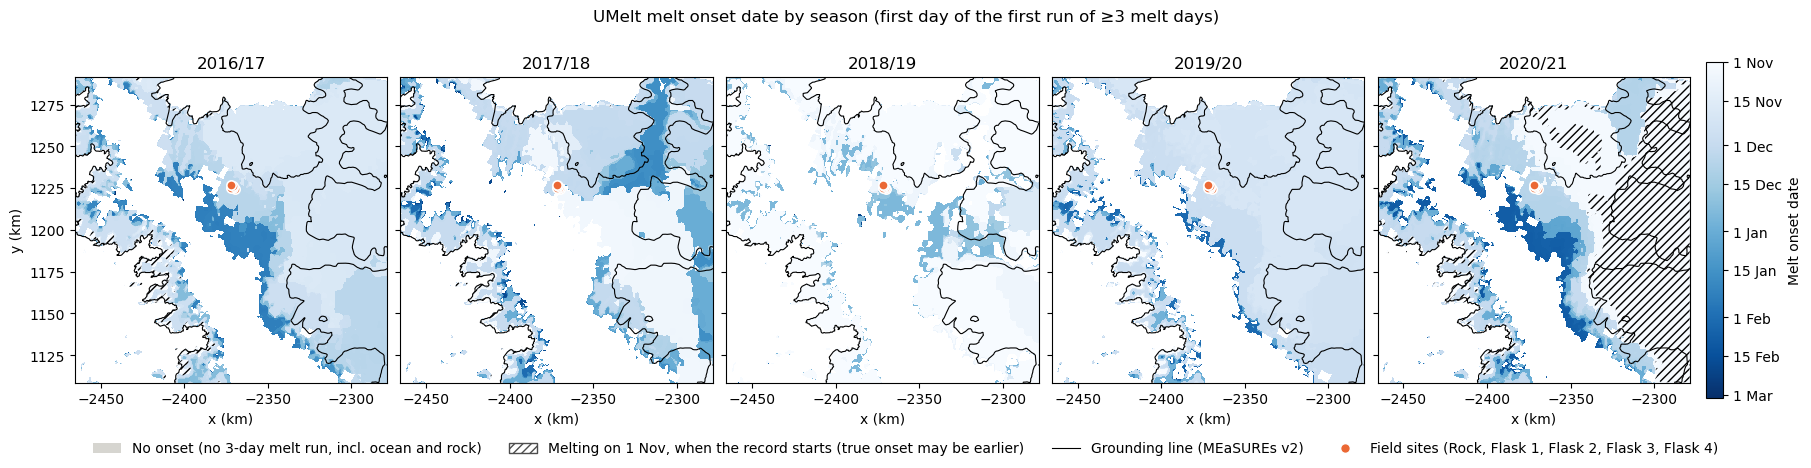

In [40]:
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
L = 2000
min_run = melt_dates.attrs["min_run"]

# onset as days since 1 Nov of each season, so all seasons share one colour scale
nov1 = xr.DataArray(pd.to_datetime([f"{s}-11-01" for s in melt_dates.season.values]),
                    coords={"season": melt_dates.season})
onset_day = (melt_dates.onset - nov1).dt.days

# half-month colour bins from 1 Nov to 1 Mar on a single-hue ramp (light = early, dark = late)
edges = [0, 14, 30, 44, 61, 75, 92, 106, 120]
edge_labels = ["1 Nov", "15 Nov", "1 Dec", "15 Dec", "1 Jan", "15 Jan", "1 Feb", "15 Feb", "1 Mar"]
cmap = 'Blues'
# cmap = mcolors.LinearSegmentedColormap.from_list(
#     "onset", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
# cmap.set_bad("#d6d5d0")  # no melt run long enough to define an onset
# norm = mcolors.BoundaryNorm(edges, cmap.N, extend="max")

# grounding line (clipped to the map, so it doesn't zoom the axes out) and field sites, in km
gl_km = gl.to_crs(melt.rio.crs).boundary.clip(melt.rio.bounds()).scale(1e-3, 1e-3, origin=(0, 0))
sites_km = points.geometry.scale(1e-3, 1e-3, origin=(0, 0))
gl_style = dict(color="black", linewidth=0.8)
site_style = dict(marker="o", s=45, facecolor="#eb6834", edgecolor="white", linewidth=1.2, zorder=3)

fig, axes = plt.subplots(1, onset_day.sizes["season"], figsize=(18, 4.6), sharex=True, sharey=True,
                         layout="constrained")
x_km, y_km = onset_day.x / 1e3, onset_day.y / 1e3
for ax, season in zip(axes, onset_day.season.values):
    im = ax.pcolormesh(x_km, y_km, onset_day.sel(season=season), cmap=cmap,)
    censored = melt_dates.onset_censored.sel(season=season)
    if censored.any():
        ax.contourf(x_km, y_km, censored, levels=[0.5, 1.5], colors="none", hatches=["////"])
    gl_km.plot(ax=ax, **gl_style)
    ax.scatter(sites_km.x, sites_km.y, **site_style)
    ax.set_title(f"{season}/{str(season + 1)[-2:]}")
    ax.set_aspect("equal")
    ax.set_xlabel("x (km)")
axes[0].set_ylabel("y (km)")

cbar = fig.colorbar(im, ax=axes, ticks=edges, shrink=0.85, pad=0.01)
cbar.ax.set_yticklabels(edge_labels)
cbar.ax.invert_yaxis()  # earliest at the top, like a calendar
cbar.set_label("Melt onset date")
fig.legend(
    handles=[
        mpatches.Patch(facecolor="#d6d5d0",
                       label=f"No onset (no {min_run}-day melt run, incl. ocean and rock)"),
        mpatches.Patch(facecolor="white", edgecolor="0.3", hatch="////",
                       label="Melting on 1 Nov, when the record starts (true onset may be earlier)"),
        Line2D([], [], label="Grounding line (MEaSUREs v2)", **gl_style),
        Line2D([], [], linestyle="none", marker="o", markersize=7, markerfacecolor="#eb6834",
               markeredgecolor="white", label=f"Field sites ({', '.join(points['Site'])})"),
    ],
    loc="outside lower center", ncols=4, frameon=False,
)
fig.suptitle(f"UMelt melt onset date by season (first day of the first run of ≥{min_run} melt days)")
plt.show()

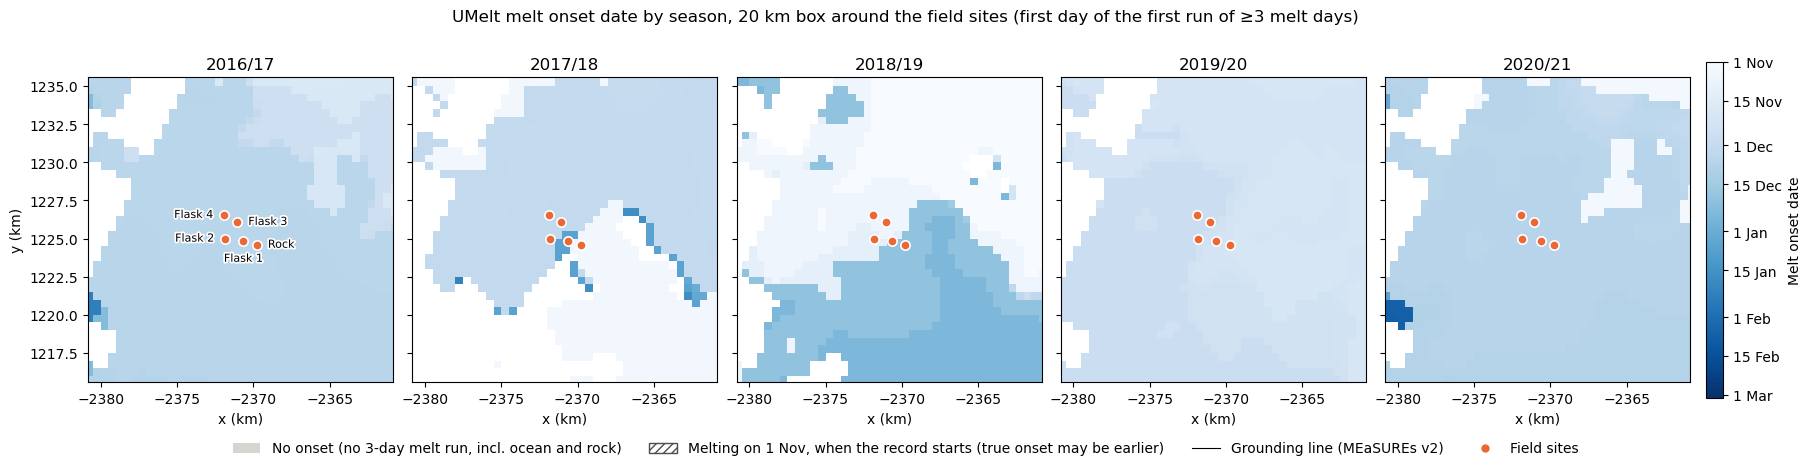

In [42]:
import matplotlib.patheffects as patheffects

# same maps, zoomed to a 20 km x 20 km box centred on the field sites
# (uses the colour scale, grounding line and site styles from the cell above)
box_km = 20
site_minx, site_miny, site_maxx, site_maxy = sites_km.total_bounds
cx, cy = (site_minx + site_maxx) / 2, (site_miny + site_maxy) / 2

fig, axes = plt.subplots(1, onset_day.sizes["season"], figsize=(18, 4.6), sharex=True, sharey=True,
                         layout="constrained")
for ax, season in zip(axes, onset_day.season.values):
    im = ax.pcolormesh(x_km, y_km, onset_day.sel(season=season), cmap=cmap,)
    censored = melt_dates.onset_censored.sel(season=season)
    if censored.any():
        ax.contourf(x_km, y_km, censored, levels=[0.5, 1.5], colors="none", hatches=["////"])
    gl_km.plot(ax=ax, **gl_style)
    ax.scatter(sites_km.x, sites_km.y, **site_style)
    ax.set_title(f"{season}/{str(season + 1)[-2:]}")
    ax.set_aspect("equal")
    ax.set_xlabel("x (km)")
axes[0].set_xlim(cx - box_km / 2, cx + box_km / 2)
axes[0].set_ylim(cy - box_km / 2, cy + box_km / 2)
axes[0].set_ylabel("y (km)")

# name the sites once, on the first panel; offsets (points) are set by hand so names don't overlap
label_offsets = {"Rock": (8, 0), "Flask 1": (0, -9), "Flask 2": (-8, 0), "Flask 3": (8, 0), "Flask 4": (-8, 0)}
for name, pt in zip(points["Site"], sites_km):
    dx, dy = label_offsets.get(name, (8, 0))
    axes[0].annotate(
        name, (pt.x, pt.y), xytext=(dx, dy), textcoords="offset points", fontsize=8,
        ha="left" if dx > 0 else "right" if dx < 0 else "center",
        va="bottom" if dy > 0 else "top" if dy < 0 else "center",
        path_effects=[patheffects.withStroke(linewidth=2.5, foreground="white")],
    )

cbar = fig.colorbar(im, ax=axes, ticks=edges, shrink=0.85, pad=0.01)
cbar.ax.set_yticklabels(edge_labels)
cbar.ax.invert_yaxis()  # earliest at the top, like a calendar
cbar.set_label("Melt onset date")
fig.legend(
    handles=[
        mpatches.Patch(facecolor="#d6d5d0",
                       label=f"No onset (no {min_run}-day melt run, incl. ocean and rock)"),
        mpatches.Patch(facecolor="white", edgecolor="0.3", hatch="////",
                       label="Melting on 1 Nov, when the record starts (true onset may be earlier)"),
        Line2D([], [], label="Grounding line (MEaSUREs v2)", **gl_style),
        Line2D([], [], linestyle="none", marker="o", markersize=7, markerfacecolor="#eb6834",
               markeredgecolor="white", label="Field sites"),
    ],
    loc="outside lower center", ncols=4, frameon=False,
)
fig.suptitle(f"UMelt melt onset date by season, {box_km} km box around the field sites "
             f"(first day of the first run of ≥{min_run} melt days)")
plt.show()